# ISIC 2019 — DermaFedNet (Centralized Training)
PyTorch. Runs in a VS Code Jupyter notebook with the Anaconda kernel `fl-isic`.

**This version has no federated learning and no hashing/encryption:** one model is trained on the whole
training set with a standard training loop (no Flower, no clients, no rounds, no SHA-256, no AES, no secure aggregation).

**Custom model — DermaFedNet:** ImageNet-pretrained ConvNeXt V2 encoder → CBAM channel+spatial attention
→ two branches: (a) GeM pooling, (b) 2-layer Transformer encoder over the 8×8 feature tokens (global context)
→ fused MLP classifier.

**Schedule:** up to `EPOCHS` epochs with cosine LR decay, early stopping on the validation set, the best epoch is kept.
Everything is printed per epoch and saved to OUTPUT_DIR. The test set is used once at the very end.

First run a smoke test: SUBSET_FRACTION = 0.1, EPOCHS = 2.

## 1. Imports

In [1]:
import os, sys, gc, io, math, json, time, copy, random, warnings, logging, traceback
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from PIL import Image, ImageFile
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, classification_report, confusion_matrix,
                             roc_curve, auc)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms



ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore", category=UserWarning)

print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | "
      f"torchvision {__import__('torchvision').__version__}")
print("CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

Python 3.11.16 | torch 2.9.1+cu126 | torchvision 0.24.1+cu126
CUDA available: True | NVIDIA GeForce RTX 4090


## 2. Configuration — edit only this cell

In [2]:
# ---------- Paths ----------
LOCAL_DATA_DIR = r"F:\rakib\dataset"                     # ISIC 2019 (class folders MEL, NV, ... or CSV)
OUTPUT_DIR = Path("./central_isic_outputs").resolve()    # everything is saved here
CACHE_DIR  = Path("./isic_cache_288").resolve()          # resized copy of the images (created once)

# ---------- Data ----------
SUBSET_FRACTION = 1.0           # smoke test: 0.1
IMG_SIZE   = 256                # model input (must be a multiple of 32)
CACHE_SIZE = 288                # images resized once (shorter side) -> much faster training
VAL_FRAC, TEST_FRAC = 0.10, 0.20

# ---------- Training ----------
EPOCHS      = 50                # maximum number of epochs
EARLY_STOP  = True              # stop when the validation metric stops improving (best epoch is kept)
PATIENCE    = 8                 # ... after this many epochs without improvement
SELECT_METRIC = "acc"           # best epoch chosen on validation: "acc" or "bal_acc" (ISIC official)

# ---------- Model / optimisation ----------
PRETRAINED   = True             # ImageNet-pretrained ConvNeXt encoder (strongly recommended)
BATCH_SIZE   = 32               # reduce to 16 if CUDA runs out of memory
LR_BACKBONE  = 1e-4             # AdamW, encoder
LR_HEAD      = 1e-3             # AdamW, CBAM + Transformer + classifier (randomly initialised)
LR_MIN_FACTOR = 0.05            # cosine decay down to 5% of the base LR
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
USE_CLASS_WEIGHTS = True        # square-root inverse-frequency class weights (imbalanced ISIC)
USE_AMP = True                  # mixed precision on GPU
USE_TTA = True                  # test-time augmentation (4 flips) for the final test report

# ---------- Saving / logging ----------
RESUME = True                   # if a run was interrupted, continue from the last saved epoch
PRINT_EVERY = 1                 # print every N epochs

# ---------- Hardware ----------
NUM_WORKERS = 0 if os.name == "nt" else min(4, os.cpu_count() or 1)   # Windows: 0

SEED = 42
MODEL_NAME = "DermaFedNet"
os.environ.setdefault("PYTHONUTF8", "1")
os.environ.setdefault("PYTHONIOENCODING", "utf-8")

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
seed_everything()

assert IMG_SIZE % 32 == 0, "IMG_SIZE must be a multiple of 32"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LOG_FILE = OUTPUT_DIR / "run_log.txt"

def log(msg: str = ""):
    """Print to the notebook output and append to OUTPUT_DIR/run_log.txt."""
    print(msg, flush=True)
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(msg + "\n")

CONFIG = {k: (str(v) if isinstance(v, Path) else v) for k, v in globals().items()
          if k.isupper() and isinstance(v, (int, float, str, bool, Path))}
with open(OUTPUT_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)
log(f"\n=== New session {time.strftime('%Y-%m-%d %H:%M:%S')} | device {DEVICE} | output {OUTPUT_DIR} ===")



=== New session 2026-10-11 13:49:30 | device cuda | output F:\Rakib\central_isic_outputs ===


## 3. Dataset discovery (class folders or ISIC ground-truth CSV, auto-detected)

Dataset: F:\rakib\dataset | 25331 images | 8 classes: ['AK', 'BCC', 'BKL', 'DF', 'MEL', 'NV', 'SCC', 'VASC']


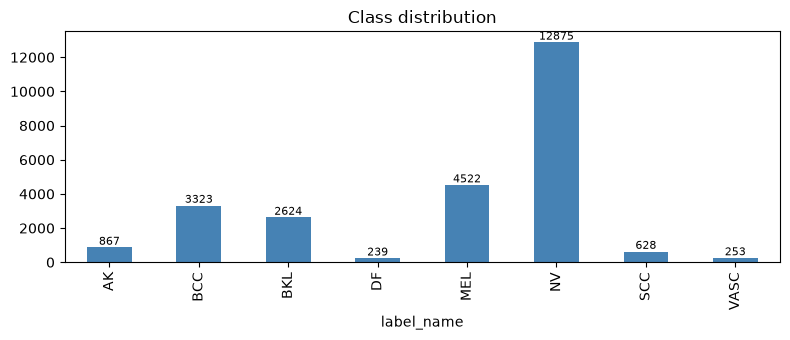

In [3]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def discover_dataset(root: Path) -> pd.DataFrame:
    """Return DataFrame[path, label_name]. Supports
    (a) class sub-folders at any depth (MEL/, NV/, ...; split folders are merged) and
    (b) ISIC_2019_Training_GroundTruth.csv (one-hot) + an image folder."""
    files = [p for p in root.rglob("*") if p.suffix.lower() in IMG_EXTS]
    if not files:
        raise RuntimeError(f"No images found under {root}")
    csvs = [c for c in root.rglob("*.csv") if "groundtruth" in c.name.lower()]
    parents = pd.Series([p.parent.name for p in files])
    if csvs and parents.nunique() < 3:          # (b) CSV layout
        gt = pd.read_csv(csvs[0])
        cls_cols = [c for c in gt.columns if c not in ("image", "UNK") and gt[c].sum() > 0]
        gt["label_name"] = gt[cls_cols].idxmax(axis=1)
        by_stem = {p.stem: str(p.resolve()) for p in files}
        gt["path"] = gt["image"].map(by_stem)
        df = gt.dropna(subset=["path"])[["path", "label_name"]]
    else:                                        # (a) folder-per-class layout
        df = pd.DataFrame({"path": [str(p.resolve()) for p in files], "label_name": parents.values})
    df["stem"] = df["path"].map(lambda s: Path(s).stem)
    df = df.drop_duplicates(subset=["stem", "label_name"]).drop(columns="stem")
    return df.reset_index(drop=True)

DATA_ROOT = Path(LOCAL_DATA_DIR).expanduser()
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"LOCAL_DATA_DIR not found: {DATA_ROOT}")
df_all = discover_dataset(DATA_ROOT)
CLASS_NAMES = sorted(df_all["label_name"].unique())
NUM_CLASSES = len(CLASS_NAMES)
df_all["label"] = df_all["label_name"].map({c: i for i, c in enumerate(CLASS_NAMES)})
log(f"Dataset: {DATA_ROOT} | {len(df_all)} images | {NUM_CLASSES} classes: {CLASS_NAMES}")

if SUBSET_FRACTION < 1.0:
    df_all, _ = train_test_split(df_all, train_size=SUBSET_FRACTION,
                                 stratify=df_all["label"], random_state=SEED)
    df_all = df_all.reset_index(drop=True)
    log(f"Using stratified subset: {len(df_all)} images")

counts = df_all["label_name"].value_counts().reindex(CLASS_NAMES)
ax = counts.plot.bar(figsize=(8, 3.5), color="steelblue", title="Class distribution")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150); plt.show()

## 4. One-time resize cache
Many ISIC images are 1024px+; decoding them every epoch is slow. Done once, skipped on later runs.

In [4]:
def cache_one(args):
    """Resize one image (shorter side -> CACHE_SIZE) and save it as JPEG in CACHE_DIR."""
    src, dst = args
    if dst.exists():
        return
    try:
        with Image.open(src) as im:
            im = im.convert("RGB")
            w, h = im.size
            s = CACHE_SIZE / min(w, h)
            if s < 1:
                im = im.resize((max(1, round(w * s)), max(1, round(h * s))), Image.BICUBIC)
            dst.parent.mkdir(parents=True, exist_ok=True)
            im.save(dst, "JPEG", quality=95)
    except Exception as e:
        print("Failed:", src, e)

jobs = [(Path(p), CACHE_DIR / ln / (Path(p).stem + ".jpg"))
        for p, ln in zip(df_all["path"], df_all["label_name"])]
with ThreadPoolExecutor(max_workers=max(4, (os.cpu_count() or 2) * 2)) as ex:
    list(tqdm(ex.map(cache_one, jobs), total=len(jobs), desc="Caching"))
df_all["path"] = [str(d.resolve()) for _, d in jobs]
df_all = df_all[df_all["path"].map(os.path.exists)].reset_index(drop=True)
log(f"Cached images: {len(df_all)} -> {CACHE_DIR}")

Caching:   0%|          | 0/25331 [00:00<?, ?it/s]

Cached images: 25331 -> F:\Rakib\isic_cache_288


## 5. Split (train / val / test)
The split is done on the ORIGINAL images, so no image can appear in two sets. Validation selects the best epoch; test is used once at the very end.

In [5]:
df_trainpool, df_test = train_test_split(df_all, test_size=TEST_FRAC,
                                         stratify=df_all["label"], random_state=SEED)
df_train, df_val = train_test_split(df_trainpool, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                    stratify=df_trainpool["label"], random_state=SEED)
df_train, df_val, df_test = (d.reset_index(drop=True) for d in (df_train, df_val, df_test))
log(f"Split: train {len(df_train)} | val {len(df_val)} | test {len(df_test)}")

split_counts = pd.DataFrame({n: d["label_name"].value_counts().reindex(CLASS_NAMES).fillna(0).astype(int)
                             for n, d in [("train", df_train), ("val", df_val), ("test", df_test)]})
split_counts.to_csv(OUTPUT_DIR / "split_class_counts.csv")
print(split_counts)


Split: train 17731 | val 2533 | test 5067
            train   val  test
label_name                   
AK            607    87   173
BCC          2326   332   665
BKL          1837   262   525
DF            167    24    48
MEL          3166   452   904
NV           9012  1288  2575
SCC           439    63   126
VASC          177    25    51


## 6. PyTorch Dataset and transforms

In [6]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
TRAIN_TF = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.8, 1.25)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(180),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.03),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.1))])
EVAL_TF = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.125)), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ISICDataset(Dataset):
    """Dataset over a list of (image_path, label) records."""
    def __init__(self, records, tf):
        self.records, self.tf = records, tf
    def __len__(self):
        return len(self.records)
    def __getitem__(self, i):
        path, label = self.records[i]
        with Image.open(path) as im:
            x = self.tf(im.convert("RGB"))
        return x, int(label)

def make_loader(records, train: bool, batch_size: int = BATCH_SIZE):
    return DataLoader(ISICDataset(records, TRAIN_TF if train else EVAL_TF),
                      batch_size=batch_size, shuffle=train,
                      drop_last=train and len(records) > batch_size,
                      num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

TRAIN_RECORDS = list(zip(df_train["path"], df_train["label"]))
VAL_RECORDS  = list(zip(df_val["path"], df_val["label"]))
TEST_RECORDS = list(zip(df_test["path"], df_test["label"]))

## 7. Custom model — DermaFedNet
```
image 256×256 ─► ConvNeXt-Tiny encoder (ImageNet) ─► LayerNorm ─► CBAM (channel + spatial attention)
                                                                   ├─► GeM pooling ───────────────┐
                                                                   └─► 1×1 proj ─► 64 tokens       │
                                                                       + pos-embedding             │
                                                                       ─► 2× Transformer encoder   │
                                                                       ─► mean token ──────────────┤
                                                                      concat (768+384) ─► MLP ─► 8 classes
```

In [7]:
! pip install timm

In [8]:
from torchvision import models
from torchvision.models.convnext import LayerNorm2d
import timm
 
class CBAM(nn.Module):
    """Convolutional Block Attention Module: channel attention followed by spatial attention."""
    def __init__(self, channels, reduction=16, kernel_size=7):
        super().__init__()
        self.mlp = nn.Sequential(nn.Conv2d(channels, channels // reduction, 1), nn.GELU(),
                                 nn.Conv2d(channels // reduction, channels, 1))
        self.spatial = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2)
 
    def forward(self, x):
        ca = torch.sigmoid(self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1)))
        x = x * ca
        sa = torch.sigmoid(self.spatial(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))
        return x * sa
 
class GeM(nn.Module):
    """Generalised-mean pooling with a learnable exponent p (computed in float32 for AMP safety)."""
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p, self.eps = nn.Parameter(torch.ones(1) * p), eps
 
    def forward(self, x):
        with torch.autocast(device_type=x.device.type, enabled=False):
            p = self.p.float().clamp(1.0, 6.0)
            x = x.float().clamp(min=self.eps).pow(p)
            return F.adaptive_avg_pool2d(x, 1).pow(1.0 / p).flatten(1)
 
class DermaFedNet(nn.Module):
    def __init__(self, num_classes, img_size=256, pretrained=False,
                 embed_dim=384, depth=2, heads=6, drop=0.3):
        super().__init__()
        # ConvNeXt V2 Base (timm). Use "convnextv2_base.fcmae_ft_in1k" for the ImageNet-1k-only weights.
        cnx = timm.create_model("convnextv2_base.fcmae_ft_in22k_in1k", pretrained=pretrained, num_classes=0)
        self.backbone = nn.Sequential(cnx.stem, cnx.stages)   # 1024 × (img/32) × (img/32)
        self.norm = cnx.head.norm                              # pretrained LayerNorm2d(1024)
        c = 1024
        self.cbam = CBAM(c)
        self.gem = GeM()
        self.proj = nn.Conv2d(c, embed_dim, 1)
        n_tokens = (img_size // 32) ** 2
        self.pos = nn.Parameter(torch.zeros(1, n_tokens, embed_dim))
        nn.init.trunc_normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(embed_dim, heads, embed_dim * 2, dropout=0.1,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.tok_norm = nn.LayerNorm(embed_dim)
        self.head = nn.Sequential(nn.LayerNorm(c + embed_dim), nn.Dropout(drop),
                                  nn.Linear(c + embed_dim, 512), nn.GELU(), nn.Dropout(0.2),
                                  nn.Linear(512, num_classes))
 
    def forward(self, x):
        f = self.cbam(self.norm(self.backbone(x)))
        g = self.gem(f)                                         # local texture / colour statistics
        t = self.proj(f).flatten(2).transpose(1, 2) + self.pos  # (B, tokens, embed)
        t = self.tok_norm(self.transformer(t)).mean(1)          # global lesion context
        return self.head(torch.cat([g.float(), t.float()], 1))
 
    def param_groups(self):
        enc = list(self.backbone.parameters()) + list(self.norm.parameters())
        enc_ids = {id(p) for p in enc}
        head = [p for p in self.parameters() if id(p) not in enc_ids]
        return [{"params": enc, "lr": LR_BACKBONE, "name": "encoder"},
                {"params": head, "lr": LR_HEAD, "name": "head"}]
 
def build_model(pretrained=False):
    return DermaFedNet(NUM_CLASSES, IMG_SIZE, pretrained=pretrained)
 
_m = build_model(PRETRAINED)                              # also downloads the ImageNet weights once
with torch.no_grad():
    out = _m.eval()(torch.randn(2, 3, IMG_SIZE, IMG_SIZE))
log(f"{MODEL_NAME}: {sum(p.numel() for p in _m.parameters())/1e6:.2f}M parameters | output {tuple(out.shape)}")
with open(OUTPUT_DIR / "model_architecture.txt", "w") as f:
    f.write(str(_m))
del _m, out; gc.collect()


DermaFedNet: 91.34M parameters | output (2, 8)


60

## 8. Training / evaluation helpers and metrics

In [9]:
def class_weights_from(records, num_classes):
    counts = np.bincount([l for _, l in records], minlength=num_classes).astype(float)
    w = np.where(counts > 0, np.sqrt(counts.sum() / (num_classes * np.maximum(counts, 1))), 0.0)
    w = w / w[counts > 0].mean()
    return torch.tensor(w, dtype=torch.float32)

def train_one_epoch(model, loader, opt, scaler, crit, device):
    model.train()
    amp = USE_AMP and device.type == "cuda"
    total, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            out = model(x)
            loss = crit(out, y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        total += loss.item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += y.size(0)
    return total / max(n, 1), correct / max(n, 1)

@torch.no_grad()
def predict(model, loader, device, tta=False):
    """Return (mean loss, labels, softmax probabilities). tta=True averages 4 flipped views."""
    model.to(device).eval()
    amp = USE_AMP and device.type == "cuda"
    crit = nn.CrossEntropyLoss(reduction="sum")
    loss, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        views = [x, x.flip(-1), x.flip(-2), x.flip(-1).flip(-2)] if tta else [x]
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            prob = torch.stack([torch.softmax(model(v).float(), 1) for v in views]).mean(0)
        loss += F.nll_loss(torch.log(prob.clamp_min(1e-8)), y, reduction="sum").item()
        ys.append(y.cpu()); ps.append(prob.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return loss / len(y), y, p

def compute_metrics(y, prob, num_classes):
    pred = prob.argmax(1)
    m = {"acc": accuracy_score(y, pred),
         "bal_acc": balanced_accuracy_score(y, pred),
         "precision_macro": precision_score(y, pred, average="macro", zero_division=0),
         "recall_macro": recall_score(y, pred, average="macro", zero_division=0),
         "f1_macro": f1_score(y, pred, average="macro", zero_division=0)}
    try:
        m["auc_macro"] = roc_auc_score(y, prob, multi_class="ovr", average="macro",
                                       labels=list(range(num_classes)))
    except ValueError:
        m["auc_macro"] = float("nan")
    return m

def epoch_lr_factor(ep, total):
    """Cosine decay over all epochs (1.0 -> LR_MIN_FACTOR)."""
    t = (ep - 1) / max(1, total - 1)
    return LR_MIN_FACTOR + (1 - LR_MIN_FACTOR) * 0.5 * (1 + math.cos(math.pi * t))

def append_csv(path: Path, row: dict):
    new = not path.exists()
    pd.DataFrame([row]).to_csv(path, mode="a", header=new, index=False)


## 9. Train the model
If the run stops (power cut, crash), just run this cell again: with RESUME = True it continues from the last saved epoch (`last_checkpoint.pt`).

In [ ]:
train_loader = make_loader(TRAIN_RECORDS, True)
val_loader   = make_loader(VAL_RECORDS, False, BATCH_SIZE * 2)

model = build_model(pretrained=PRETRAINED).to(DEVICE)
opt = torch.optim.AdamW(model.param_groups(), weight_decay=WEIGHT_DECAY)
base_lrs = [g["lr"] for g in opt.param_groups]
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and DEVICE.type == "cuda")
cw = class_weights_from(TRAIN_RECORDS, NUM_CLASSES).to(DEVICE) if USE_CLASS_WEIGHTS else None
crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=LABEL_SMOOTHING)

CKPT = OUTPUT_DIR / "last_checkpoint.pt"
HISTORY, best, wait, start_ep, finished = [], {SELECT_METRIC: -1.0, "epoch": 0}, 0, 1, False

if RESUME and CKPT.exists():
    ck = torch.load(CKPT, map_location="cpu", weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
    HISTORY, best, wait, finished = ck["history"], ck["best"], ck["wait"], ck["finished"]
    start_ep = ck["epoch"] + 1
    log(f"RESUME: continuing after epoch {ck['epoch']} (best {SELECT_METRIC} {best[SELECT_METRIC]:.4f} at epoch {best['epoch']})")
else:
    for f in ["epoch_log.csv", "best_model.pt", "final_model.pt", "last_checkpoint.pt"]:
        (OUTPUT_DIR / f).unlink(missing_ok=True)

if finished or start_ep > EPOCHS:
    log("Training already finished — go to the evaluation cells.")
else:
    log(f"\n{'=' * 100}\n{MODEL_NAME} | centralized training | epochs {start_ep}-{EPOCHS} | "
        f"train {len(TRAIN_RECORDS)} | val {len(VAL_RECORDS)}\n{'=' * 100}")
    seed_everything()
    t_run = time.time()
    for ep in range(start_ep, EPOCHS + 1):
        for g, base in zip(opt.param_groups, base_lrs):
            g["lr"] = base * epoch_lr_factor(ep, EPOCHS)
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, opt, scaler, crit, DEVICE)
        va_loss, y, p = predict(model, val_loader, DEVICE)
        m = compute_metrics(y, p, NUM_CLASSES)
        m.update(epoch=ep, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss,
                 lr_encoder=opt.param_groups[0]["lr"], lr_head=opt.param_groups[1]["lr"],
                 epoch_min=(time.time() - t0) / 60)
        improved = m[SELECT_METRIC] > best[SELECT_METRIC] + 1e-4
        if improved:
            best = {SELECT_METRIC: m[SELECT_METRIC], "epoch": ep}
            torch.save(model.state_dict(), OUTPUT_DIR / "best_model.pt")
            wait = 0
        else:
            wait += 1
        m["best"] = improved
        HISTORY.append(m)
        append_csv(OUTPUT_DIR / "epoch_log.csv", m)
        stop = EARLY_STOP and wait >= PATIENCE
        if ep % PRINT_EVERY == 0 or improved or stop or ep == EPOCHS:
            log(f"[Epoch {ep:3d}/{EPOCHS}] train_loss {tr_loss:.4f} train_acc {tr_acc:.4f} | "
                f"val_loss {va_loss:.4f} val_acc {m['acc']:.4f} val_bal_acc {m['bal_acc']:.4f} "
                f"f1 {m['f1_macro']:.4f} auc {m['auc_macro']:.4f} | {m['epoch_min']:.1f} min"
                + ("  *best*" if improved else ""))
        done = stop or ep == EPOCHS
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                    "epoch": ep, "history": HISTORY, "best": best, "wait": wait, "finished": done}, CKPT)
        if stop:
            log(f"Early stop at epoch {ep}: no {SELECT_METRIC} improvement for {PATIENCE} epochs.")
            break
    torch.save(model.state_dict(), OUTPUT_DIR / "final_model.pt")
    log(f"\nTraining finished | best val {SELECT_METRIC} {best[SELECT_METRIC]:.4f} at epoch {best['epoch']} "
        f"| total {(time.time() - t_run) / 3600:.2f} h")
gc.collect()


RESUME: continuing after epoch 1 (best acc 0.7240 at epoch 1)

DermaFedNet | centralized training | epochs 2-50 | train 17731 | val 2533


## 10. Learning curves

In [ ]:
H = pd.read_csv(OUTPUT_DIR / "epoch_log.csv").drop_duplicates("epoch", keep="last")
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].plot(H["epoch"], H["train_acc"], "-o", ms=3, label="train acc")
axes[0].plot(H["epoch"], H["acc"], "-s", ms=3, label="val acc")
axes[0].plot(H["epoch"], H["bal_acc"], ":D", ms=3, label="val bal_acc")
axes[0].set_title("Accuracy"); axes[0].set_ylim(0, 1)
axes[1].plot(H["epoch"], H["train_loss"], "-o", ms=3, label="train loss")
axes[1].plot(H["epoch"], H["val_loss"], "-s", ms=3, label="val loss")
axes[1].set_title("Loss")
axes[2].plot(H["epoch"], H["f1_macro"], "-o", ms=3, label="val F1 (macro)")
axes[2].plot(H["epoch"], H["auc_macro"], "-s", ms=3, label="val AUC (macro)")
axes[2].set_title("Validation F1 / AUC"); axes[2].set_ylim(0, 1)
for ax in axes:
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "learning_curves.png", dpi=150); plt.show()


## 11. Final held-out test evaluation of the best model (+ TTA) and save everything

In [ ]:
best_model = build_model(pretrained=False)
best_model.load_state_dict(torch.load(OUTPUT_DIR / "best_model.pt", map_location="cpu"))
best_epoch = int(H.loc[H[SELECT_METRIC].idxmax(), "epoch"])
test_loader = make_loader(TEST_RECORDS, False, BATCH_SIZE * 2)

results = {}
for name, tta in [("no_tta", False)] + ([("tta", True)] if USE_TTA else []):
    loss, y_test, p = predict(best_model, test_loader, DEVICE, tta=tta)
    results[name] = {"test_loss": loss, **compute_metrics(y_test, p, NUM_CLASSES)}
    if tta or not USE_TTA:
        p_final = p
final_key = "tta" if USE_TTA else "no_tta"
results["best_epoch"] = best_epoch
results["select_metric"] = SELECT_METRIC
with open(OUTPUT_DIR / "test_metrics.json", "w") as f:
    json.dump(results, f, indent=2)

report = classification_report(y_test, p_final.argmax(1), target_names=CLASS_NAMES, digits=4, zero_division=0)
with open(OUTPUT_DIR / "classification_report.txt", "w") as f:
    f.write(f"{MODEL_NAME} — best model (epoch {best_epoch}), test set, {final_key}\n\n{report}")
pred_df = pd.DataFrame({"path": [r[0] for r in TEST_RECORDS], "true": [CLASS_NAMES[i] for i in y_test],
                        "pred": [CLASS_NAMES[i] for i in p_final.argmax(1)]})
for i, c in enumerate(CLASS_NAMES):
    pred_df[f"prob_{c}"] = p_final[:, i]
pred_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

log(f"\n{'=' * 110}\nFINAL TEST — {MODEL_NAME}, best model from epoch {best_epoch} (selected by {SELECT_METRIC} on val)")
for name in [k for k in ("no_tta", "tta") if k in results]:
    r = results[name]
    log(f"  {name:6s} | acc {r['acc']:.4f} | bal_acc {r['bal_acc']:.4f} | precision {r['precision_macro']:.4f} | "
        f"recall {r['recall_macro']:.4f} | f1 {r['f1_macro']:.4f} | auc {r['auc_macro']:.4f}")
log(report)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, norm, fmt, title in [(axes[0], None, "d", "counts"), (axes[1], "true", ".2f", "normalized")]:
    cm = confusion_matrix(y_test, p_final.argmax(1), labels=range(NUM_CLASSES), normalize=norm)
    sns.heatmap(cm, annot=True, fmt=fmt, cmap="Blues", ax=ax, cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"Confusion matrix ({title})"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150); plt.show()

plt.figure(figsize=(7, 6))
for c in range(NUM_CLASSES):
    if (y_test == c).any():
        fpr, tpr, _ = roc_curve(y_test == c, p_final[:, c])
        plt.plot(fpr, tpr, label=f"{CLASS_NAMES[c]} (AUC {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(f"{MODEL_NAME} — one-vs-rest ROC (test)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=150); plt.show()

log("\nSaved files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    log(f"  {p.name:40s} {p.stat().st_size / 2**20:9.2f} MB")